# Praktikum 1 — Mengenal Data Runtun Waktu: Komponen, Pola, dan Validasi Data

---

Nama: Safina Zahra  
NIM: 52250033  
Mata kuliah: Analisis Runtun Waktu  
Program studi: Sains Data, Institut Teknologi Sains Bandung  
Dosen pengampu: Bakti Siregar, S.Si., M.Sc  
Materi: Bab 1 — Pengantar Analisis Runtun Waktu (Latihan 1.1, 1.2, 1.3)

---

## Gambaran umum

**Tujuan.** Praktikum ini melatih tiga hal: (1) mengenali komponen sebuah deret waktu (tren, musiman, siklus, derau) dan menentukan apakah polanya aditif atau multiplikatif; (2) membuat deret sintetis untuk membuktikan bahwa pola yang kita tanam memang bisa terbaca balik; (3) menyiapkan dan memvalidasi dataset yang akan dipakai sepanjang Tugas 1.

**Alur kerja.**
1. Memuat lima deret contoh dan melihat karakternya (Latihan 1.1).
2. Membangun deret harian sintetis dengan tren menurun dan pola mingguan (Latihan 1.2).
3. Membuat fungsi `validasi_deret`, lalu memakainya pada dataset Tugas 1, yaitu inflasi bulanan Indonesia (gabungan 90 kota, BPS) (Latihan 1.3).

**Cara membaca laporan ini.** Setiap bagian diakhiri kotak *Interpretasi* yang menjelaskan arti angka dan grafik, bukan hanya menampilkannya.


## 0. Persiapan

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from pandas.plotting import lag_plot
from scipy.signal import periodogram

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'figure.figsize': (10, 3.4)})

SEED = 52250033                      # pakai NIM supaya hasil acak bisa diulang
BRN = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/'
RDS = 'https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/'

## 1. Memuat data & galeri lima deret (Bab 1.2–1.3)

In [2]:
# Airline: data bulanan, indeks dijadikan tanggal dan frekuensinya ditetapkan
penumpang = pd.read_csv(BRN + 'airline-passengers.csv', parse_dates=['Month'], index_col='Month')['Passengers']
penumpang.index.freq = 'MS'
print('tipe indeks :', type(penumpang.index).__name__, '| freq =', penumpang.index.freqstr, '| n =', len(penumpang))
print('rentang     :', penumpang.index.min().date(), 'sampai', penumpang.index.max().date())
penumpang.head()

tipe indeks : DatetimeIndex | freq = MS | n = 144
rentang     : 1949-01-01 sampai 1960-12-01


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


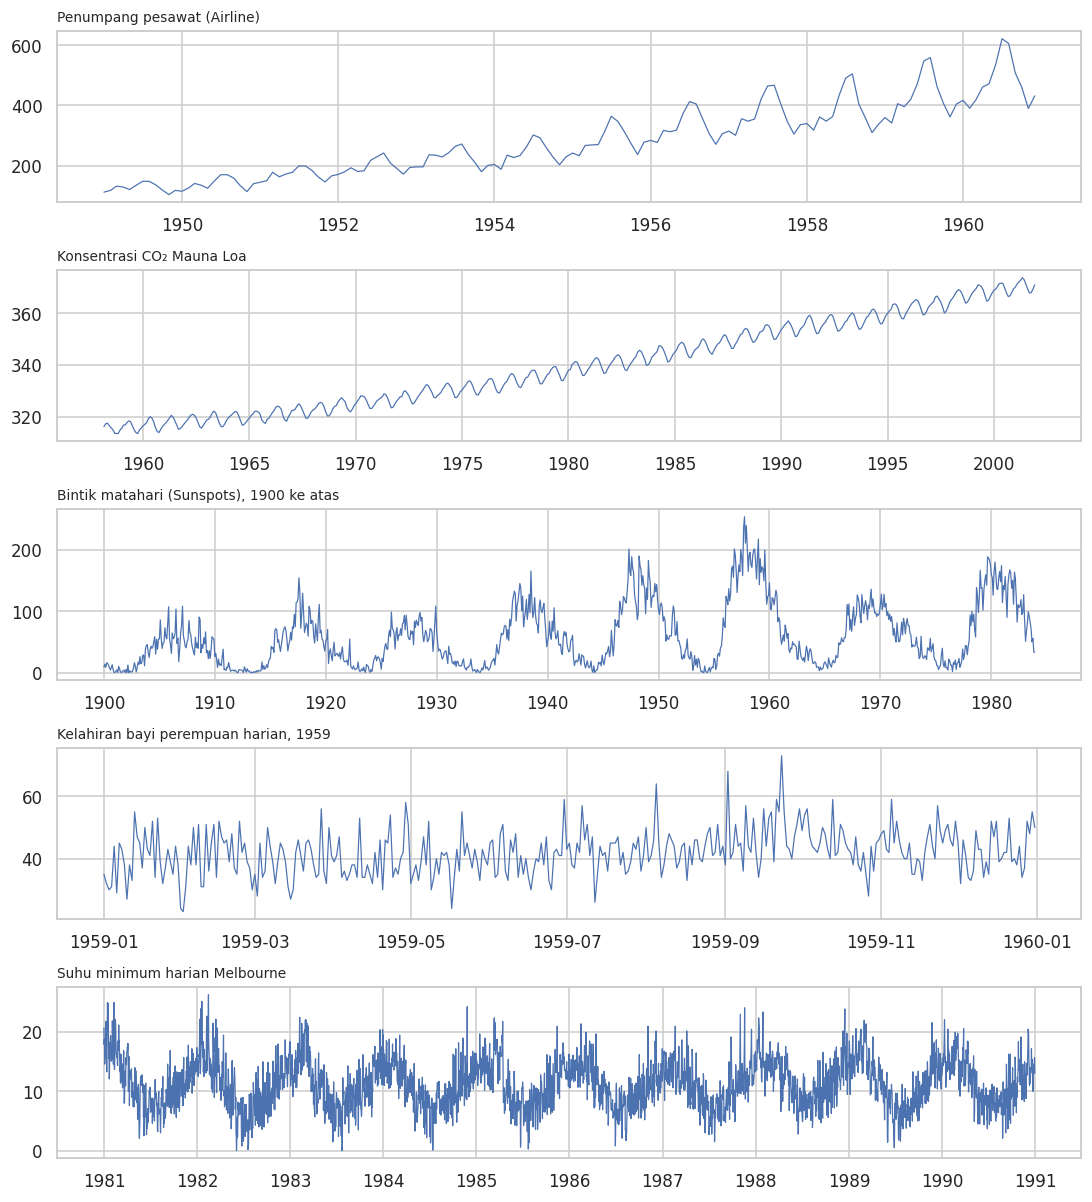

In [3]:
co2_bulanan = sm.datasets.co2.load_pandas().data['co2'].resample('MS').mean().interpolate()
matahari    = pd.read_csv(BRN + 'monthly-sunspots.csv', parse_dates=['Month'], index_col='Month')['Sunspots']
lahir_harian = pd.read_csv(BRN + 'daily-total-female-births.csv', parse_dates=['Date'], index_col='Date')['Births']
suhu_melb   = pd.read_csv(BRN + 'daily-min-temperatures.csv', parse_dates=['Date'], index_col='Date')['Temp']

galeri = [
    (penumpang,             'Penumpang pesawat (Airline)'),
    (co2_bulanan,           'Konsentrasi CO₂ Mauna Loa'),
    (matahari['1900':],     'Bintik matahari (Sunspots), 1900 ke atas'),
    (lahir_harian,          'Kelahiran bayi perempuan harian, 1959'),
    (suhu_melb,             'Suhu minimum harian Melbourne'),
]
fig, axs = plt.subplots(5, 1, figsize=(10, 11))
for ax, (s, judul) in zip(axs, galeri):
    ax.plot(s.index, s.values, lw=.8)
    ax.set_title(judul, loc='left', fontsize=9)
plt.tight_layout(); plt.show()

> **Interpretasi grafik.** Kelima deret tampak sangat berbeda, padahal semuanya data berurutan waktu.
> - *Airline* naik tajam dan gelombang musimannya makin lebar seiring naiknya level, ciri khas pola multiplikatif.
> - *CO₂* naik halus dengan gelombang tahunan yang lebarnya hampir sama dari tahun ke tahun, ciri pola aditif.
> - *Bintik matahari* naik-turun dengan jarak antarpuncak yang tidak persis sama, jadi ini **siklus**, bukan musiman.
> - *Kelahiran harian* hanya berfluktuasi acak di sekitar satu nilai tengah, hampir tanpa pola.
> - *Suhu Melbourne* membentuk gelombang tahunan yang rapi tetapi tanpa kecenderungan naik atau turun.


## 2. Latihan 1.1 — Identifikasi komponen
Angka pendukung untuk tiap deret dihitung di sel berikut.

In [4]:
def rentang_tahunan(s):
    g = s.groupby(s.index.year)
    return g.max() - g.min()

ra, rc = rentang_tahunan(penumpang), rentang_tahunan(co2_bulanan)
print('[Airline] rentang max-min per tahun, 1949 -> 1960 :', ra.iloc[0], '->', ra.iloc[-1], f'(naik {ra.iloc[-1]/ra.iloc[0]:.1f}x)')
print('[Airline] rata-rata 1949 -> 1960 (ribu)            :', round(penumpang['1949'].mean(), 1), '->', round(penumpang['1960'].mean(), 1))
print('[CO2]     rentang max-min per tahun, awal -> akhir :', round(rc.iloc[0], 1), '->', round(rc.iloc[-1], 1))
print('[CO2]     rata-rata 12 bulan pertama -> terakhir   :', round(co2_bulanan.iloc[:12].mean(), 1), '->', round(co2_bulanan.iloc[-12:].mean(), 1), 'ppm')

x = matahari['1900':]
f, p = periodogram(x.values - x.values.mean())
f, p = f[1:], p[1:]
print('\n[Sunspots] periode dominan dari periodogram :', round(1 / f[p.argmax()] / 12, 1), 'tahun')
print('[Sunspots] nilai minimum dan maksimum       :', x.min(), 'dan', x.max())

print('\n[Kelahiran] rata-rata / simpangan baku / CV :', round(lahir_harian.mean(), 1), '/', round(lahir_harian.std(), 1), '/', f'{lahir_harian.std() / lahir_harian.mean():.0%}')
print('[Kelahiran] autokorelasi lag 1              :', round(lahir_harian.autocorr(1), 3))

per_bulan = suhu_melb.groupby(suhu_melb.index.month).mean()
per_tahun = suhu_melb.groupby(suhu_melb.index.year).mean()
print('\n[Suhu] bulan terdingin / terhangat (rata-rata):', per_bulan.idxmin(), round(per_bulan.min(), 1), '/', per_bulan.idxmax(), round(per_bulan.max(), 1))
print('[Suhu] rata-rata tahunan 1981 vs 1990          :', round(per_tahun.iloc[0], 2), 'vs', round(per_tahun.iloc[-1], 2))

[Airline] rentang max-min per tahun, 1949 -> 1960 : 44 -> 232 (naik 5.3x)
[Airline] rata-rata 1949 -> 1960 (ribu)            : 126.7 -> 476.2
[CO2]     rentang max-min per tahun, awal -> akhir : 4.0 -> 5.9
[CO2]     rata-rata 12 bulan pertama -> terakhir   : 315.4 -> 370.9 ppm

[Sunspots] periode dominan dari periodogram : 10.5 tahun
[Sunspots] nilai minimum dan maksimum       : 0.0 dan 253.8

[Kelahiran] rata-rata / simpangan baku / CV : 42.0 / 7.3 / 18%
[Kelahiran] autokorelasi lag 1              : 0.218

[Suhu] bulan terdingin / terhangat (rata-rata): 7 6.7 / 2 15.4
[Suhu] rata-rata tahunan 1981 vs 1990          : 11.52 vs 11.67


### Jawaban Latihan 1.1

| Deret | Komponen yang tampak | Aditif / multiplikatif | Angka pendukung |
|---|---|---|---|
| Airline | Tren naik + musiman periode 12 (puncak Juli–Agustus) | **Multiplikatif** | Rentang max–min per tahun naik dari 44 (1949) ke 232 (1960), yaitu 5,3×; rata-rata 126,7 ke 476,2 ribu |
| CO₂ Mauna Loa | Tren naik halus + musiman periode 12 | **Aditif** | Rentang tahunan hanya berubah 4,0 ke 5,9 ppm, padahal rata-rata naik 315,4 ke 370,9 ppm |
| Bintik matahari | **Siklus** (periode tidak tetap), tanpa musiman tetap | Tidak berlaku | Periode dominan periodogram ±10,5 tahun; nilai bulanan 0 sampai 253,8 |
| Kelahiran harian | Hanya **derau** di sekitar rata-rata | Tidak berlaku | Rata-rata 42,0; simpangan baku 7,3 (CV 18%); autokorelasi lag 1 hanya 0,218 |
| Suhu minimum Melbourne | **Musiman tahunan** kuat, tanpa tren | **Aditif** | Rata-rata bulanan terendah Juli 6,7 °C, tertinggi Februari 15,4 °C; rata-rata tahunan 11,52 (1981) vs 11,67 (1990) |

> **Interpretasi.** Cara paling cepat membedakan aditif dan multiplikatif adalah membandingkan lebar gelombang musiman di awal dan akhir data. Di Airline lebarnya membesar 5,3 kali mengikuti level, sedangkan di CO₂ nyaris tetap. Melbourne berada di belahan bumi selatan, sehingga bulan terdingin justru Juli. Rata-rata tahunan suhu hampir tidak berubah (11,52 vs 11,67 °C), jadi tren dianggap tidak ada. Untuk bintik matahari, periode ±10,5 tahun cocok dengan siklus matahari yang dikenal 9–14 tahun, dan karena panjangnya tidak tetap, model musiman biasa tidak cocok.


## 3. Latihan 1.2 — Deret sintetis harian (3 tahun)
Tren menurun + musiman mingguan (periode 7) + derau acak.

indeks berurutan: True | duplikat: False | freq: D | n = 1095


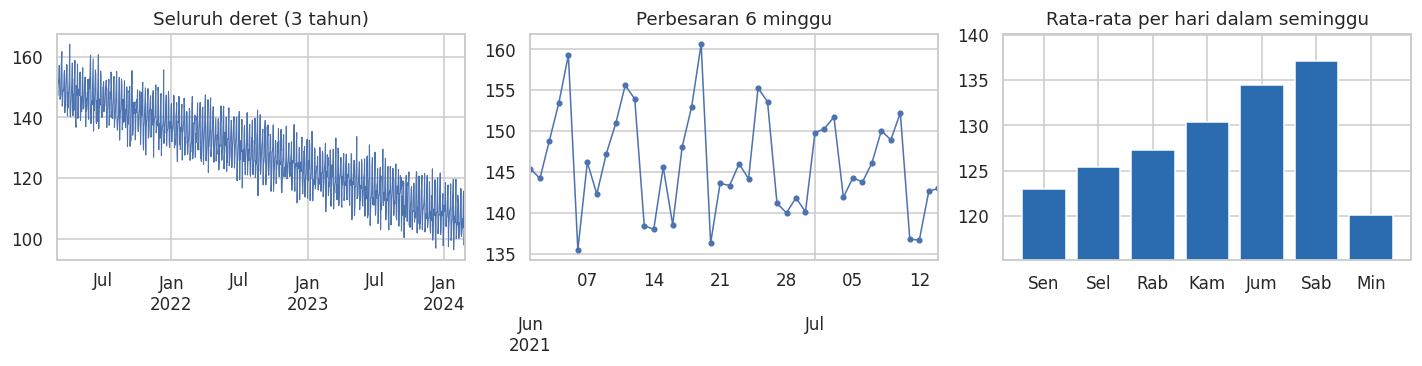

              Sen     Sel     Rab     Kam    Jum     Sab     Min
rata-rata  122.94  125.34  127.22  130.35  134.5  137.12  120.09
selisih hari tertinggi - terendah : 17.03
rata-rata tahun 1 -> tahun 3      : 142.9 -> 113.6
autokorelasi lag 7 (data di-diff) : 0.792


In [5]:
rng = np.random.default_rng(SEED)
n = 3 * 365
t = np.arange(n)
tgl = pd.date_range('2021-03-01', periods=n, freq='D')

tren = 150 - 0.04 * t                                   # menurun pelan
efek_hari = np.array([-5., -3., -1., 2., 6., 9., -8.])  # Senin ... Minggu
efek_hari -= efek_hari.mean()
musiman = efek_hari[tgl.dayofweek]                      # periode 7
derau = rng.normal(0, 2.5, n)
sintetis = pd.Series(tren + musiman + derau, index=tgl, name='nilai')

print('indeks berurutan:', sintetis.index.is_monotonic_increasing, '| duplikat:', sintetis.index.has_duplicates,
      '| freq:', pd.infer_freq(sintetis.index), '| n =', len(sintetis))

hari = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
rata_hari = sintetis.groupby(sintetis.index.dayofweek).mean()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
sintetis.plot(ax=ax[0], lw=.7, title='Seluruh deret (3 tahun)')
sintetis['2021-06-01':'2021-07-14'].plot(ax=ax[1], lw=1, marker='o', ms=3, title='Perbesaran 6 minggu')
ax[2].bar(hari, rata_hari.values, color='#2b6cb0')
ax[2].set_ylim(rata_hari.min() - 5, rata_hari.max() + 3)
ax[2].set_title('Rata-rata per hari dalam seminggu')
plt.tight_layout(); plt.show()

print(rata_hari.round(2).rename(dict(enumerate(hari))).to_frame('rata-rata').T)
print('selisih hari tertinggi - terendah :', round(rata_hari.max() - rata_hari.min(), 2))
print('rata-rata tahun 1 -> tahun 3      :', round(sintetis['2021-03':'2022-02'].mean(), 1), '->', round(sintetis['2023-03':'2024-02'].mean(), 1))
print('autokorelasi lag 7 (data di-diff) :', round(sintetis.diff().autocorr(7), 3))

### Jawaban Latihan 1.2

| Hari | Sen | Sel | Rab | Kam | Jum | Sab | Min |
|---|---|---|---|---|---|---|---|
| Rata-rata | 122,94 | 125,34 | 127,22 | 130,35 | 134,50 | **137,12** | **120,09** |

> **Interpretasi.** Pola mingguan yang kita tanam terbaca jelas dari data: Sabtu tertinggi (137,12) dan Minggu terendah (120,09), selisihnya 17,03. Tren menurun terlihat dari rata-rata tahun pertama 142,9 yang turun menjadi 113,6 di tahun ketiga. Setelah tren dibuang dengan selisih pertama, autokorelasi pada lag 7 mencapai 0,792. Angka setinggi itu berarti nilai hari ini sangat mirip dengan nilai tepat seminggu sebelumnya, dan itu bukti periode musimannya 7 hari.


## 4. Latihan 1.3 — Persiapan Tugas 1

### 4.1 Fungsi validasi data
Fungsi ini memastikan indeks bertipe tanggal, berurutan, tidak ganda, berfrekuensi tetap, dan menghitung celah tanggal.

In [6]:
def validasi_deret(s, freq=None):
    """Cek kontrak data deret waktu; berikan galat yang jelas jika dilanggar."""
    if not isinstance(s.index, pd.DatetimeIndex):
        raise TypeError('indeks harus DatetimeIndex (pakai parse_dates / pd.to_datetime)')
    if not s.index.is_monotonic_increasing:
        raise ValueError('indeks belum berurutan, pakai sort_index()')
    if s.index.has_duplicates:
        raise ValueError(f'ada {s.index.duplicated().sum()} tanggal ganda')
    freq = freq or pd.infer_freq(s.index)
    if freq is None:
        raise ValueError('frekuensi tidak terdeteksi, kemungkinan ada celah tanggal (coba asfreq)')
    celah = s.asfreq(freq).isna().sum() - s.isna().sum()
    return {'n': len(s), 'freq': freq, 'awal': s.index[0].date(), 'akhir': s.index[-1].date(), 'celah': int(celah)}

# uji pada tiga kasus yang sengaja dibuat salah
salah_tipe  = pd.Series([3, 1, 2], index=['10/2024', '2/2024', '9/2024'])
ada_celah   = suhu_melb.drop(suhu_melb.index[[100, 101, 500]])
terbalik    = penumpang.iloc[::-1]
for nama, kasus in [('tanggal berupa teks', salah_tipe), ('ada tanggal hilang', ada_celah), ('urutan terbalik', terbalik)]:
    try:
        validasi_deret(kasus)
    except (TypeError, ValueError) as e:
        print(f'ditolak ({nama}):', e)
print('Airline lolos:', validasi_deret(penumpang))

ditolak (tanggal berupa teks): indeks harus DatetimeIndex (pakai parse_dates / pd.to_datetime)
ditolak (ada tanggal hilang): frekuensi tidak terdeteksi, kemungkinan ada celah tanggal (coba asfreq)
ditolak (urutan terbalik): indeks belum berurutan, pakai sort_index()
Airline lolos: {'n': 144, 'freq': 'MS', 'awal': datetime.date(1949, 1, 1), 'akhir': datetime.date(1960, 12, 1), 'celah': 0}


> **Interpretasi.** Ketiga kasus salah ditolak dengan pesan yang jelas: tanggal berbentuk teks, tanggal hilang (frekuensi tidak terdeteksi), dan urutan terbalik. Ini penting karena pandas tidak akan memberi peringatan sendiri. Tanpa validasi, model bisa jalan dengan data yang salah dan hasilnya menyesatkan tanpa disadari. Airline lolos dengan 144 data, frekuensi bulanan (`MS`), dan 0 celah.


### 4.2 Dataset Tugas 1: inflasi bulanan Indonesia (gabungan 90 kota)
Sumber: BPS, diunduh dari portal Opendata Aceh (berkas CSV `tingkat-inflasi-bulan-ke-bulan-gabungan-90-kota-seluruh-indonesia.csv`). Nilainya persentase perubahan indeks harga konsumen dibanding bulan sebelumnya. Berkas memakai pemisah titik koma dan nama bulan bahasa Indonesia, jadi perlu dikonversi ke `DatetimeIndex`.

In [7]:
import os
FILE = 'tingkat-inflasi-bulan-ke-bulan-gabungan-90-kota-seluruh-indonesia.csv'
if not os.path.exists(FILE):                     # di Colab: unggah berkas CSV-nya dulu
    from google.colab import files
    files.upload()

mentah = pd.read_csv(FILE, sep=';')
nama_bulan = {'Januari': 1, 'Februari': 2, 'Maret': 3, 'April': 4, 'Mei': 5, 'Juni': 6,
              'Juli': 7, 'Agustus': 8, 'September': 9, 'Oktober': 10, 'November': 11, 'Desember': 12}
tanggal = pd.to_datetime(dict(year=mentah['tahun'], month=mentah['bulan'].map(nama_bulan), day=1))
y = pd.Series(mentah['tingkat_inflasi_bulanan'].values, index=pd.DatetimeIndex(tanggal, freq='MS'),
              name='inflasi_bulanan_persen')
print('nama bulan tak terpetakan:', mentah['bulan'].map(nama_bulan).isna().sum())
print(validasi_deret(y))
print(y.describe().round(3))
y.head()

Saving tingkat-inflasi-bulan-ke-bulan-gabungan-90-kota-seluruh-indonesia.csv to tingkat-inflasi-bulan-ke-bulan-gabungan-90-kota-seluruh-indonesia.csv
nama bulan tak terpetakan: 0
{'n': 231, 'freq': 'MS', 'awal': datetime.date(2006, 1, 1), 'akhir': datetime.date(2025, 3, 1), 'celah': 0}
count    231.000
mean       0.376
std        0.492
min       -0.760
25%        0.080
50%        0.270
75%        0.595
max        3.290
Name: inflasi_bulanan_persen, dtype: float64


,inflasi_bulanan_persen
2006-01-01,1.36
2006-02-01,0.58
2006-03-01,0.03
2006-04-01,0.05
2006-05-01,0.37


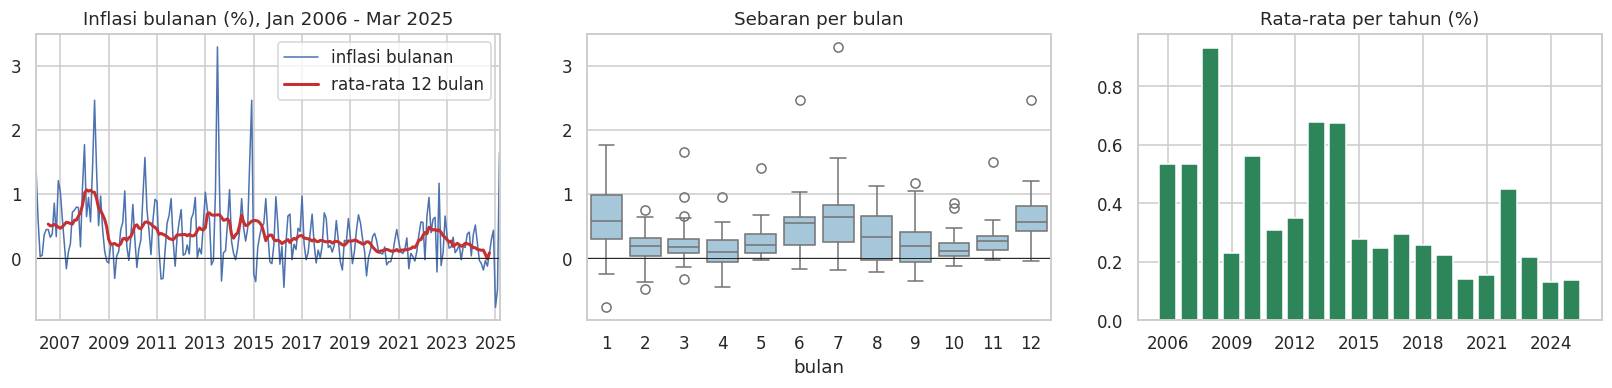

bulan negatif                       : 42 dari 231
nilai min / max                     : -0.76 Jan 2025 / 3.29 Jul 2013
lima tertinggi                      : {'Jul 2013': 3.29, 'Jun 2008': 2.46, 'Dec 2014': 2.46, 'Jan 2008': 1.77, 'Mar 2025': 1.65}
rata-rata 2006-2012 vs 2016-2024    : 0.49 vs 0.24
simpangan baku 2006-2012 vs 2016-2024: 0.5 vs 0.28
rata-rata bulan tertinggi           : {7: 0.7, 12: 0.7, 1: 0.59}
rata-rata bulan terendah            : {4: 0.12, 2: 0.19}
autokorelasi lag 1 dan lag 12       : 0.394 dan 0.295


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
y.plot(ax=ax[0], lw=1, label='inflasi bulanan')
y.rolling(12, center=True).mean().plot(ax=ax[0], lw=2, color='#c53030', label='rata-rata 12 bulan')
ax[0].axhline(0, color='k', lw=.6); ax[0].legend(); ax[0].set_title('Inflasi bulanan (%), Jan 2006 - Mar 2025')
sns.boxplot(x=y.index.month, y=y.values, ax=ax[1], color='#9ecae1')
ax[1].axhline(0, color='k', lw=.6); ax[1].set_title('Sebaran per bulan'); ax[1].set_xlabel('bulan')
rata_thn = y.groupby(y.index.year).mean()
ax[2].bar(rata_thn.index, rata_thn.values, color='#2f855a'); ax[2].set_title('Rata-rata per tahun (%)'); ax[2].set_xticks(range(2006, 2026, 3))
plt.tight_layout(); plt.show()

bln = y.groupby(y.index.month).mean()
print('bulan negatif                       :', int((y < 0).sum()), 'dari', len(y))
print('nilai min / max                     :', y.min(), y.idxmin().strftime('%b %Y'), '/', y.max(), y.idxmax().strftime('%b %Y'))
print('lima tertinggi                      :', {k.strftime('%b %Y'): v for k, v in y.nlargest(5).items()})
print('rata-rata 2006-2012 vs 2016-2024    :', round(y['2006':'2012'].mean(), 2), 'vs', round(y['2016':'2024'].mean(), 2))
print('simpangan baku 2006-2012 vs 2016-2024:', round(y['2006':'2012'].std(), 2), 'vs', round(y['2016':'2024'].std(), 2))
print('rata-rata bulan tertinggi           :', bln.nlargest(3).round(2).to_dict())
print('rata-rata bulan terendah            :', bln.nsmallest(2).round(2).to_dict())
print('autokorelasi lag 1 dan lag 12       :', round(y.autocorr(1), 3), 'dan', round(y.autocorr(12), 3))

### Jawaban Latihan 1.3 — Definisi dan dugaan komponen

**Definisi deret.** Tingkat inflasi bulanan Indonesia (gabungan 90 kota), yaitu persentase perubahan harga konsumen dibanding bulan sebelumnya. Data dicatat bulanan dari Januari 2006 sampai Maret 2025 (231 pengamatan), berfrekuensi bulanan (`MS`), dan lolos `validasi_deret` dengan 0 celah. Rata-ratanya 0,376% per bulan dengan simpangan baku 0,492. Ada 42 bulan bernilai negatif (deflasi).

**Dugaan komponen.**
- **Tren:** tidak ada tren naik atau turun yang searah. Yang tampak adalah **pergeseran level**: rata-rata 2006–2012 sebesar 0,49% turun menjadi 0,24% pada 2016–2024, dengan simpangan baku ikut turun dari 0,50 menjadi 0,28. Jadi inflasi relatif lebih jinak dan stabil di tahun-tahun belakangan.
- **Musiman periode 12:** ada, tetapi tidak sekuat data penjualan. Rata-rata bulan tertinggi adalah Juli dan Desember (sama-sama 0,70%) disusul Januari (0,59%) dan Juni (0,56%), sedangkan terendah April (0,12%). Autokorelasi lag 12 sebesar 0,295 dan lag 1 sebesar 0,394 menunjukkan ketergantungan sedang.
- **Aditif atau multiplikatif:** pasti **aditif**, karena data berupa laju perubahan yang bisa bernilai negatif (minimum −0,76% pada Januari 2025). Transformasi log tidak bisa dipakai pada nilai nol atau negatif.
- **Siklus:** tidak terlihat teratur.
- **Derau dan kejutan (outlier):** lonjakan besar Juli 2013 (3,29%), Juni 2008 (2,46%), dan Desember 2014 (2,46%), serta penurunan tajam Januari dan Februari 2025 (−0,76% dan −0,48%) yang disusul naik 1,65% pada Maret 2025. Lonjakan 2008, 2013, dan 2014 kemungkinan besar terkait kenaikan harga BBM, dan awal 2025 kemungkinan terkait kebijakan diskon tarif listrik, tetapi hal ini perlu dicek ke sumber berita resmi dan tidak bisa dibuktikan dari data ini saja.

> **Interpretasi.** Berbeda dengan data penjualan yang naik terus, inflasi bulanan berfluktuasi di sekitar nilai tengah kecil dengan kejutan besar sesekali. Karena itu kita tidak mengharapkan tren, melainkan memeriksa musiman dan level yang bergeser. Angka kejutan penting karena outlier bisa membuat uji stasioneritas dan ACF di praktikum berikutnya menyesatkan. Awal 2025 yang sangat rendah lalu melonjak juga perlu diperlakukan hati-hati, karena sangat mungkin dipicu faktor sekali waktu, bukan pola musiman.


## Kesimpulan

1. Deret waktu perlu dibaca lewat komponennya. Airline bersifat multiplikatif (rentang musiman naik 5,3×), CO₂ aditif, bintik matahari bersiklus (±10,5 tahun), kelahiran harian nyaris murni derau, dan suhu Melbourne musiman tanpa tren.
2. Deret sintetis membuktikan pola yang kita tanam dapat dikenali kembali: periode 7 hari muncul dengan autokorelasi lag 7 sebesar 0,792 setelah tren dibuang.
3. Validasi data (indeks tanggal, urutan, duplikat, frekuensi, celah) harus dilakukan sebelum pemodelan agar kesalahan tidak lolos diam-diam.
4. Dataset Tugas 1 adalah inflasi bulanan Indonesia (n = 231, Jan 2006 – Mar 2025): tanpa tren searah, tetapi levelnya bergeser turun (rata-rata 0,49% menjadi 0,24%), ada musiman ringan (Juli dan Desember tertinggi, April terendah), polanya aditif karena ada nilai negatif, dan terdapat beberapa lonjakan besar yang perlu diwaspadai.
